# Training Artificial Neural Networks (Part 1)

CSI 4106 - Fall 2026

Marcel Turcotte  
Version: Oct 15, 2026 17:35

# Preamble

## Message of the Day

<https://youtu.be/FBfNXq_R3oo>

Benaich, N. and Air Street Capital (2026).
<a href="https://www.stateof.ai/" class="external"
data-icon="true"><em>State of AI Report 2026</em></a>. Released October
8, 2026. <a href="https://youtu.be/FBfNXq_R3oo" class="external"
data-icon="true">Watch the accompanying video</a>.

The *State of AI Report 2026*, by Nathan Benaich and Air Street Capital,
surveys developments in AI research, industry, policy, and safety. The
accompanying video provides an overview of the report.

As we study how neural networks are trained, this report connects the
underlying methods to the wider field: advances in model capabilities,
the computing infrastructure that supports them, and their applications.
The report and video are supplementary resources for exploring that
broader context.

## Learning objectives

- **Trace** a feedforward network’s computation through its NumPy
  implementation.
- **Distinguish** predicted probabilities, class labels, and training
  loss.
- **Explain** how a naïve algorithm probes parameters and applies
  simultaneous updates.
- **Identify** the computational limitations that motivate
  backpropagation.

# Naïve MLP

## Data

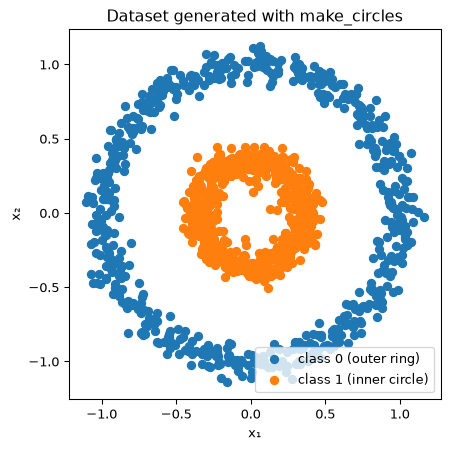

In [2]:
# Generate and plot the "circles" dataset
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Generate synthetic data
X, y = make_circles(n_samples=1200, factor=0.35, noise=0.06, random_state=42)

# Separate coordinates for plotting
x1, x2 = X[:, 0], X[:, 1]

# Plot the two classes
plt.figure(figsize=(5, 5))
plt.scatter(x1[y==0], x2[y==0], color="C0", label="class 0 (outer ring)")
plt.scatter(x1[y==1], x2[y==1], color="C1", label="class 1 (inner circle)")
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.title("Dataset generated with make_circles")
plt.axis("equal") # ensures circles look round
plt.legend()
plt.show()

Lecture 11 established how a network with fixed parameters computes
predictions. The question here is how to choose those parameters from
data. A complete NumPy implementation makes the computation and training
process accessible through programming before introducing
backpropagation.

The dataset has an outer ring (class 0) and an inner circle (class 1).
These classes are not linearly separable in the original $(x_1,x_2)$
feature space.

The training algorithm probes candidate parameter changes without
computing derivatives. Its purpose is to expose the training loop and
the cost of repeatedly evaluating the network. Backpropagation will
provide an efficient way to compute gradients in the next lecture.

## Architecture

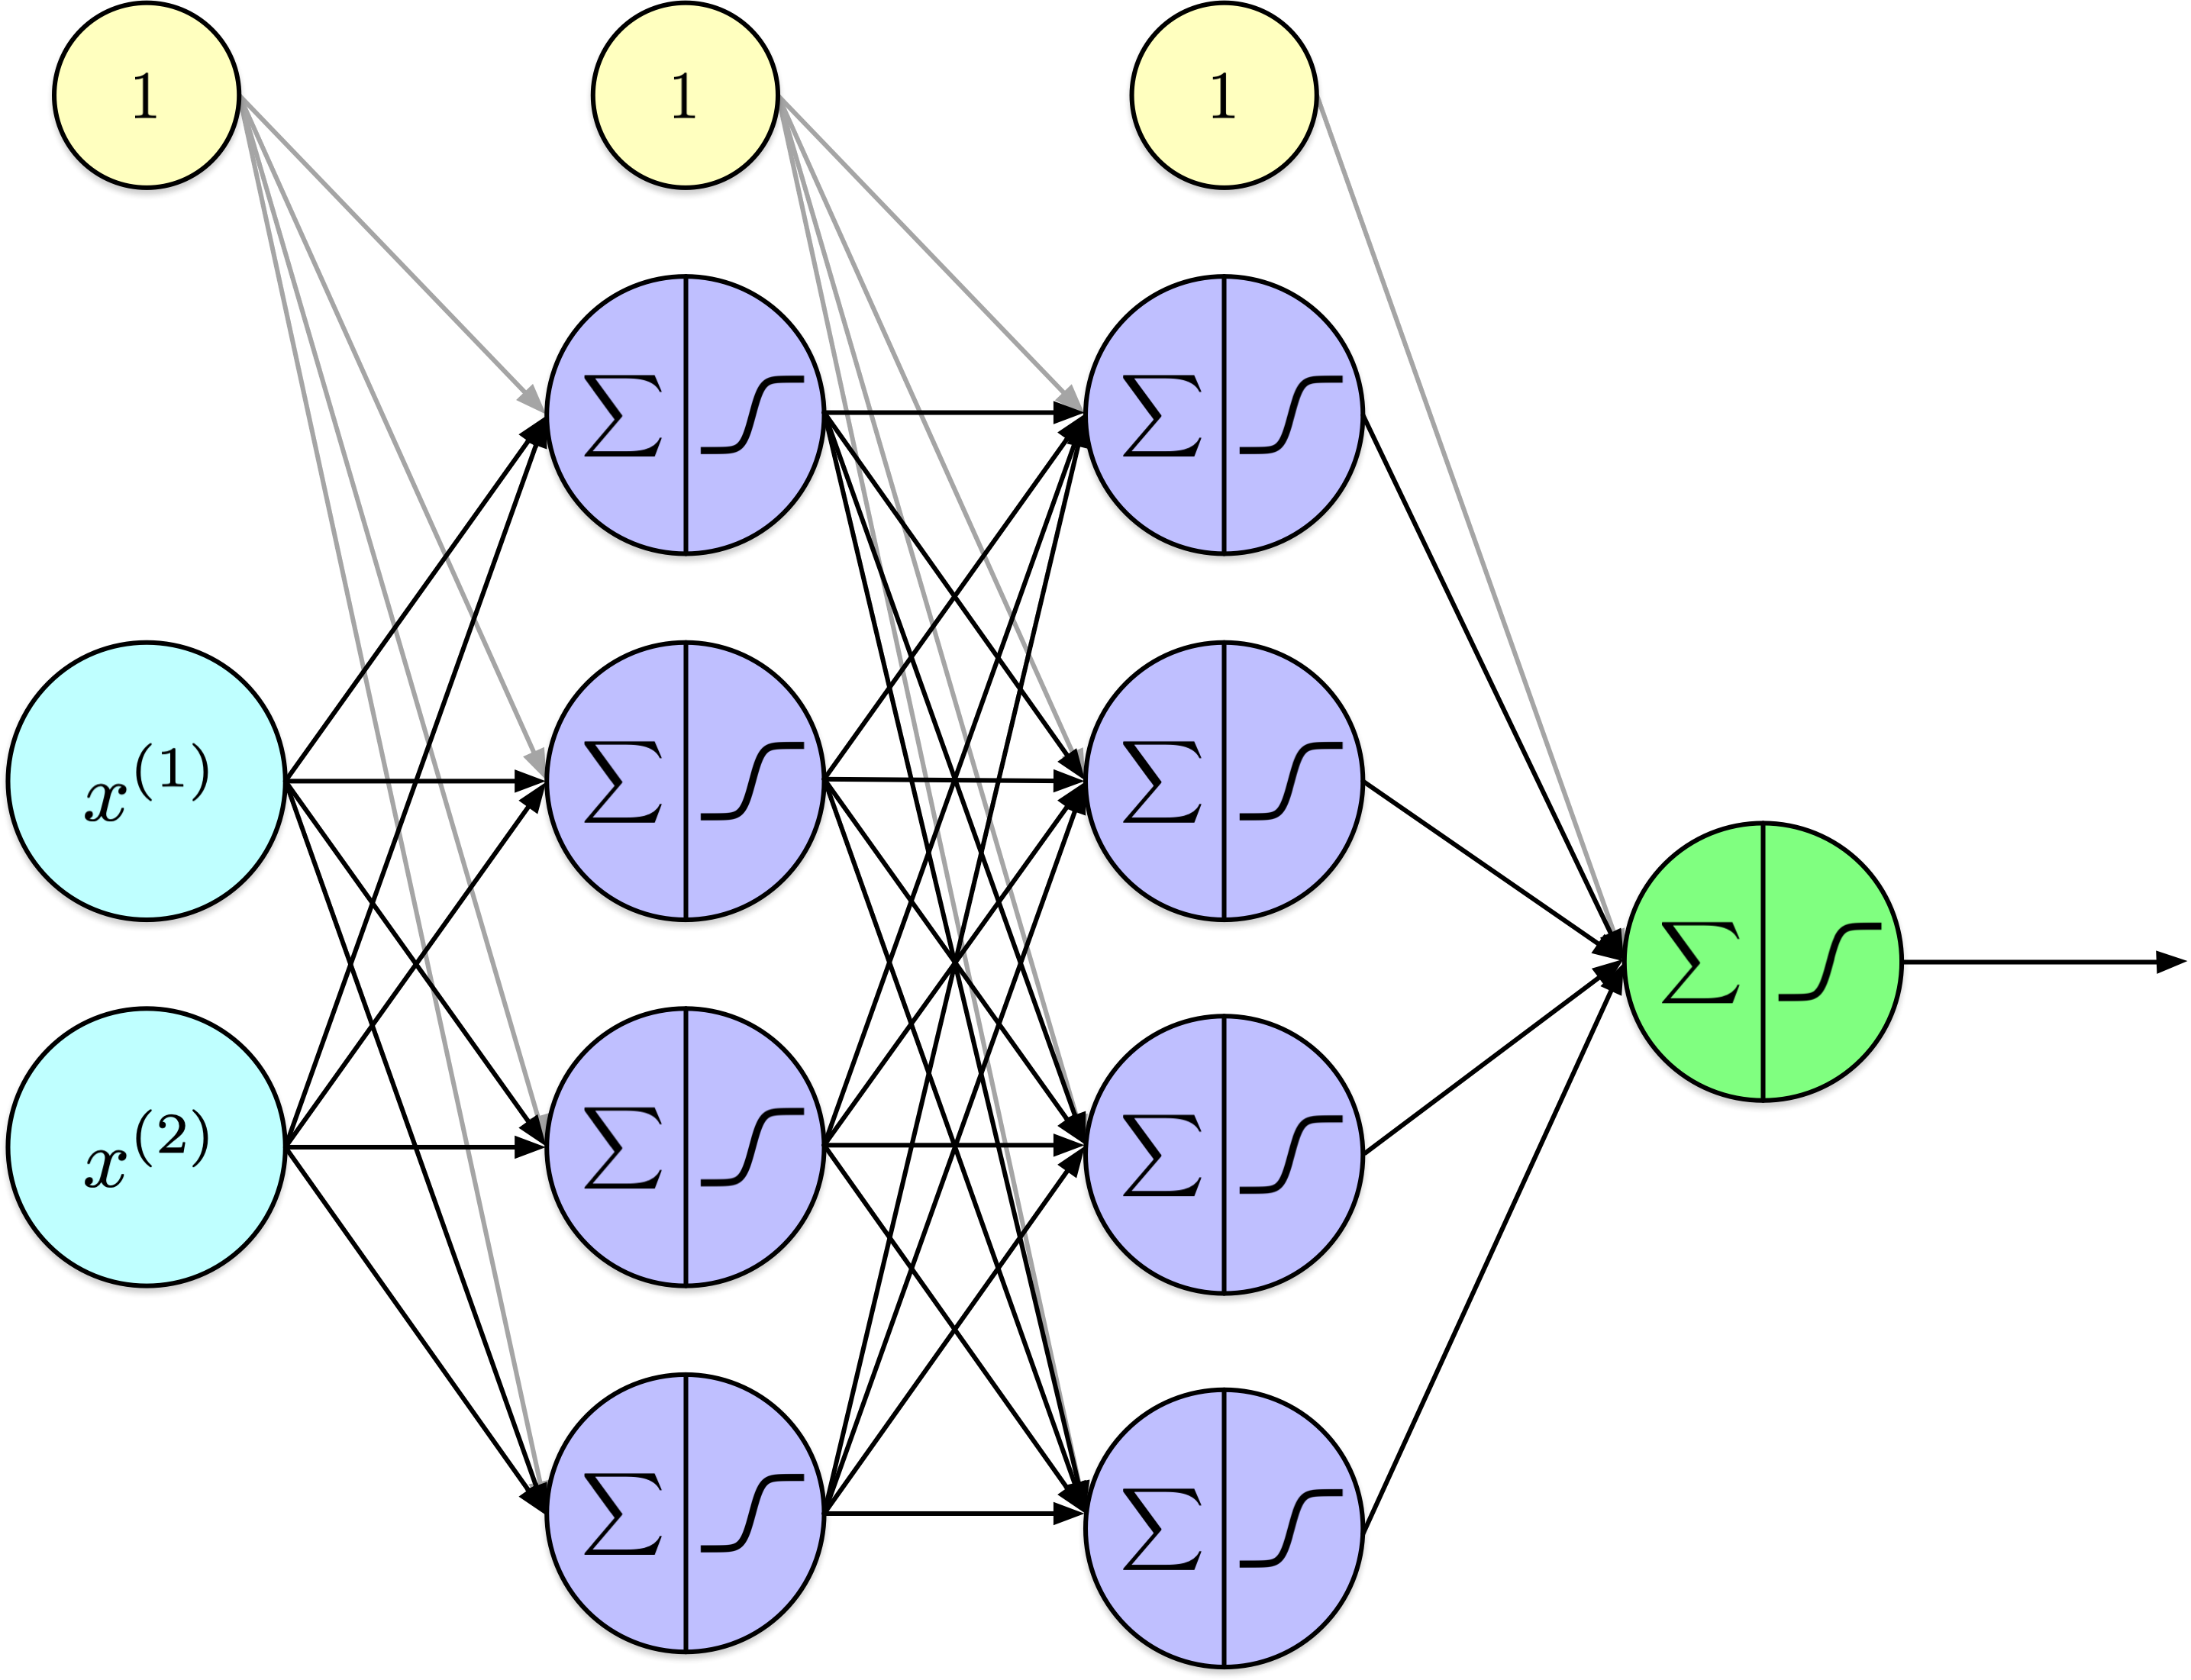

We are implementing the neural network shown above, comprising 1 input
layer with 2 units, 2 hidden layers with 4 units each, and 1 output
layer with 1 unit. We denote this architecture as \[2, 4, 4, 1\].

Our neural network, a multi-layer perceptron, is designed with two input
nodes corresponding to the two features present in our dataset. Through
our experimentation using TensorFlow Playground and Keras, as detailed
in [CircularSeparability](../11/CircularSeparability.qmd), we determined
that a configuration of two hidden layers containing four neurons each
is effective for the classification of the samples.

The network has **three parameterized layers**: two hidden layers of
four units each and one output layer with a single unit. The two input
nodes pass features into the network and are not counted as
parameterized layers.

For this implementation, every computational unit uses the sigmoid
activation function. The final output estimates the probability of
class 1. Using the same activation throughout keeps the forward-pass
code short; hidden layers are not generally required to use sigmoid.

In the visualization, the black edges between units denote the model’s
weights. Additionally, we have included three nodes that output a
constant value of 1 solely for visualization purposes; these nodes do
not have a counterpart in the actual model. The gray edges connecting
these nodes to other units represent the bias terms.

## Utilities

In [3]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def bce_loss(y_true, y_prob, eps=1e-9):

    """Binary cross-entropy loss (average over data)."""

    y_prob = np.clip(y_prob, eps, 1 - eps)

    return -np.mean(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob))

We are defining two utility functions, `sigmoid` and `bce_loss`. The
binary cross-entropy loss has the same definition as that of our
[logistic regression model](../06/slides.qmd). Do you remember another
name for binary cross-entropy loss?

In `bce_loss`, the probabilities are constrained within the interval
$[\epsilon, 1-\epsilon]$. This clipping ensures that the logarithmic
expressions $\log(0)$ and $\log(1-1) = \log(0)$ are avoided, thus
preventing undefined or infinite values during computation.

Both functions are designed to take NumPy arrays (`ndarray`) as input.
Namely, the `bce_loss` function calculates the loss for the entire
dataset without requiring explicit iteration over individual data
points.

## NaïveMLP

The complete implementation is presented below and will be examined in
the subsequent slides.

In [4]:
class NaiveMLP:

    """
    A minimal MLP for binary classification, trained with a naive
    derivative-free algorithm that applies parameter updates simultaneously.

    This deliberately simple method illustrates the training process and
    its computational cost before backpropagation is introduced.
    """

    def __init__(self, layer_sizes, step=0.1, seed=None):
        
        self.sizes = list(layer_sizes)
        self.step = float(step)
        rng = np.random.default_rng(seed)

        # Initialize weights and biases

        self.W = [rng.standard_normal(size=(in_d, out_d)) * 0.5
                  for in_d, out_d in zip(layer_sizes[:-1], layer_sizes[1:])]

        self.b = [np.zeros(out_d) for out_d in layer_sizes[1:]]

    def forward(self, X):

        """
        Simple forward pass: compute output activations only.

        X: shape (N, input_dim)

        Returns: output probabilities, shape (N,)
        """

        a = X
        for W, b in zip(self.W, self.b):
            a = sigmoid(a @ W + b)

        return a.ravel()

    def predict(self, X, threshold=0.5):

        return (self.forward(X) >= threshold).astype(int)

    def loss(self, X, y):

        return bce_loss(y, self.forward(X))

    def _all_param_tags(self):

        """
        Yields tags referencing every scalar parameter:
        ('W', layer_idx, i, j) or ('b', layer_idx, j)
        """

        for l, W in enumerate(self.W):
            for i in range(W.shape[0]):
                for j in range(W.shape[1]):
                    yield ('W', l, i, j)
            for j in range(self.b[l].shape[0]):
                yield ('b', l, j)

    def _get_param(self, tag):
        kind = tag[0]
        if kind == 'W':
            _, l, i, j = tag
            return self.W[l][i, j]
        else:
            _, l, j = tag
            return self.b[l][j]

    def _set_param(self, tag, val):
        kind = tag[0]
        if kind == 'W':
            _, l, i, j = tag
            self.W[l][i, j] = val
        else:
            _, l, j = tag
            self.b[l][j] = val

    def train(self, X, y, epochs=10, verbose=True):

        """
        Simultaneous update:
        - For each scalar parameter θ, try θ + δ for δ in {−step, 0, +step},
          pick the δ that gives minimal loss.
        - Collect all chosen δ’s, then apply all updates together.
        """

        for ep in range(1, epochs + 1):

            base_loss = self.loss(X, y)
            updates = {}

            # Probe all parameters
            for tag in self._all_param_tags():

                theta = self._get_param(tag)
                best_delta = 0.0
                best_loss = base_loss

                for delta in (-self.step, 0.0, +self.step):
                    self._set_param(tag, theta + delta)
                    trial_loss = self.loss(X, y)
                    if trial_loss < best_loss:
                        best_loss = trial_loss
                        best_delta = delta

                # restore original
                self._set_param(tag, theta)
                updates[tag] = best_delta

            # Apply all deltas together
            for tag, d in updates.items():
                if d != 0.0:
                    self._set_param(tag, self._get_param(tag) + d)

            new_loss = self.loss(X, y)

            if verbose:
                print(f"Epoch {ep:3d}: loss {base_loss:.5f} → {new_loss:.5f}")

            # optional early stop
            if abs(new_loss - base_loss) < 1e-12:
                break

To ensure the functionality of the resulting Jupyter Notebook, the whole
class has been included here.

## Class Definition

``` python
class NaiveMLP:

    """
    A minimal MLP for binary classification, trained with a naive
    derivative-free algorithm that applies parameter updates simultaneously.

    This deliberately simple method illustrates the training process and
    its computational cost before backpropagation is introduced.
    """
```

## Constructor

``` python
    def __init__(self, layer_sizes, step=0.1, seed=None):
        
        self.sizes = list(layer_sizes)
        self.step = float(step)
        rng = np.random.default_rng(seed)

        # Initialize weights and biases

        self.W = [rng.standard_normal(size=(in_d, out_d)) * 0.5
                  for in_d, out_d in zip(layer_sizes[:-1], layer_sizes[1:])]

        self.b = [np.zeros(out_d) for out_d in layer_sizes[1:]]
```

Memorizing the number of layers, the number of units per layer, and the
learning algorithm’s step size. Initializing the weights ($W$) and
biases ($b$).

## Python detour: weight arrays

In [5]:
seed = 0

rng = np.random.default_rng(seed)

layer_sizes = [2, 4, 4, 1]

[(in_d, out_d) for in_d, out_d in zip(layer_sizes[:-1], layer_sizes[1:])]

[(2, 4), (4, 4), (4, 1)]

. . .

In [6]:
[rng.standard_normal(size=(in_d, out_d)) * 0.5 for in_d, out_d in zip(layer_sizes[:-1], layer_sizes[1:])]

[array([[ 0.06286511, -0.06605243,  0.32021133,  0.05245006],
        [-0.26783469,  0.18079753,  0.65200002,  0.47354048]]),
 array([[-0.35186762, -0.63271074, -0.31163723,  0.02066299],
        [-1.16251539, -0.10939583, -0.62295547, -0.36613368],
        [-0.27212949, -0.15815008,  0.20581527,  0.52125668],
        [-0.06426733,  0.68323174, -0.33259734,  0.17575504]]),
 array([[ 0.45173509],
        [ 0.04700615],
        [-0.37174962],
        [-0.46086269]])]

How many weights has this network?

## Python detour: bias arrays

In [7]:
[out_d for out_d in layer_sizes[1:]]

[4, 4, 1]

. . .

In [8]:
[np.zeros(out_d) for out_d in layer_sizes[1:]]

[array([0., 0., 0., 0.]), array([0., 0., 0., 0.]), array([0.])]

What is the number of bias terms in this network?

The network consists of a total of 37 parameters, which include 28
weights and 9 bias terms.

## Forward Pass

Returning to the network: compute each layer’s outputs from the
preceding layer.

``` python
    def forward(self, X):

        """
        Simple forward pass: compute output activations.
        X: shape (N, input_dim)
        Returns: output probabilities, shape (N,)
        """

        a = X
        for W, b in zip(self.W, self.b):
            a = sigmoid(a @ W + b)

        return a.ravel()
```

Calculating the output activations. Determining the probability of each
instance in the dataset $X$ belonging to class 1.

The method proceeds sequentially layer-by-layer. In our running example,
this involves three distinct processing layers.

**What are `W` and `b`?**

`W` and `b` are lists, each containing three elements. The list `W`
comprises weight matrices with dimensions $2 \times 4$, $4 \times 4$,
and $4 \times 1$, while `b` consists of bias arrays sized 4, 4, and 1,
respectively.

**What is the purpose of `zip(self.W, self.b)`?**

This function pairs each weight matrix with its corresponding bias
array, producing one pair for each of the three parameterized layers.

**What does `X` represent?**

The argument `X` contains $N$ examples as rows and two features as
columns, so its shape is `(N, 2)`. In the circles training split,
$N=900$. Each iteration of the loop computes the current layer’s outputs
for all examples together.

The code uses `a` for activations: these are the unit outputs denoted by
$o$ in Lecture 11. The expression `a @ W + b` computes preactivations,
and `sigmoid(...)` produces the next activations. The final `ravel()`
converts the single output column into a one-dimensional array of
probabilities. This class assumes one output unit.

## Following the array shapes

For `layer_sizes = [2, 4, 4, 1]`, each row remains one example:

| Layer    | Incoming `a` | `W`      | `b`    | Outgoing `a` |
|:---------|:-------------|:---------|:-------|:-------------|
| Hidden 1 | `(N, 2)`     | `(2, 4)` | `(4,)` | `(N, 4)`     |
| Hidden 2 | `(N, 4)`     | `(4, 4)` | `(4,)` | `(N, 4)`     |
| Output   | `(N, 4)`     | `(4, 1)` | `(1,)` | `(N, 1)`     |

``` python
a = sigmoid(a @ W + b)
```

- `@` combines each example with the layer’s weights.
- **Broadcasting** adds the same bias vector to every row.
- `ravel()` changes the final shape from `(N, 1)` to `(N,)`.

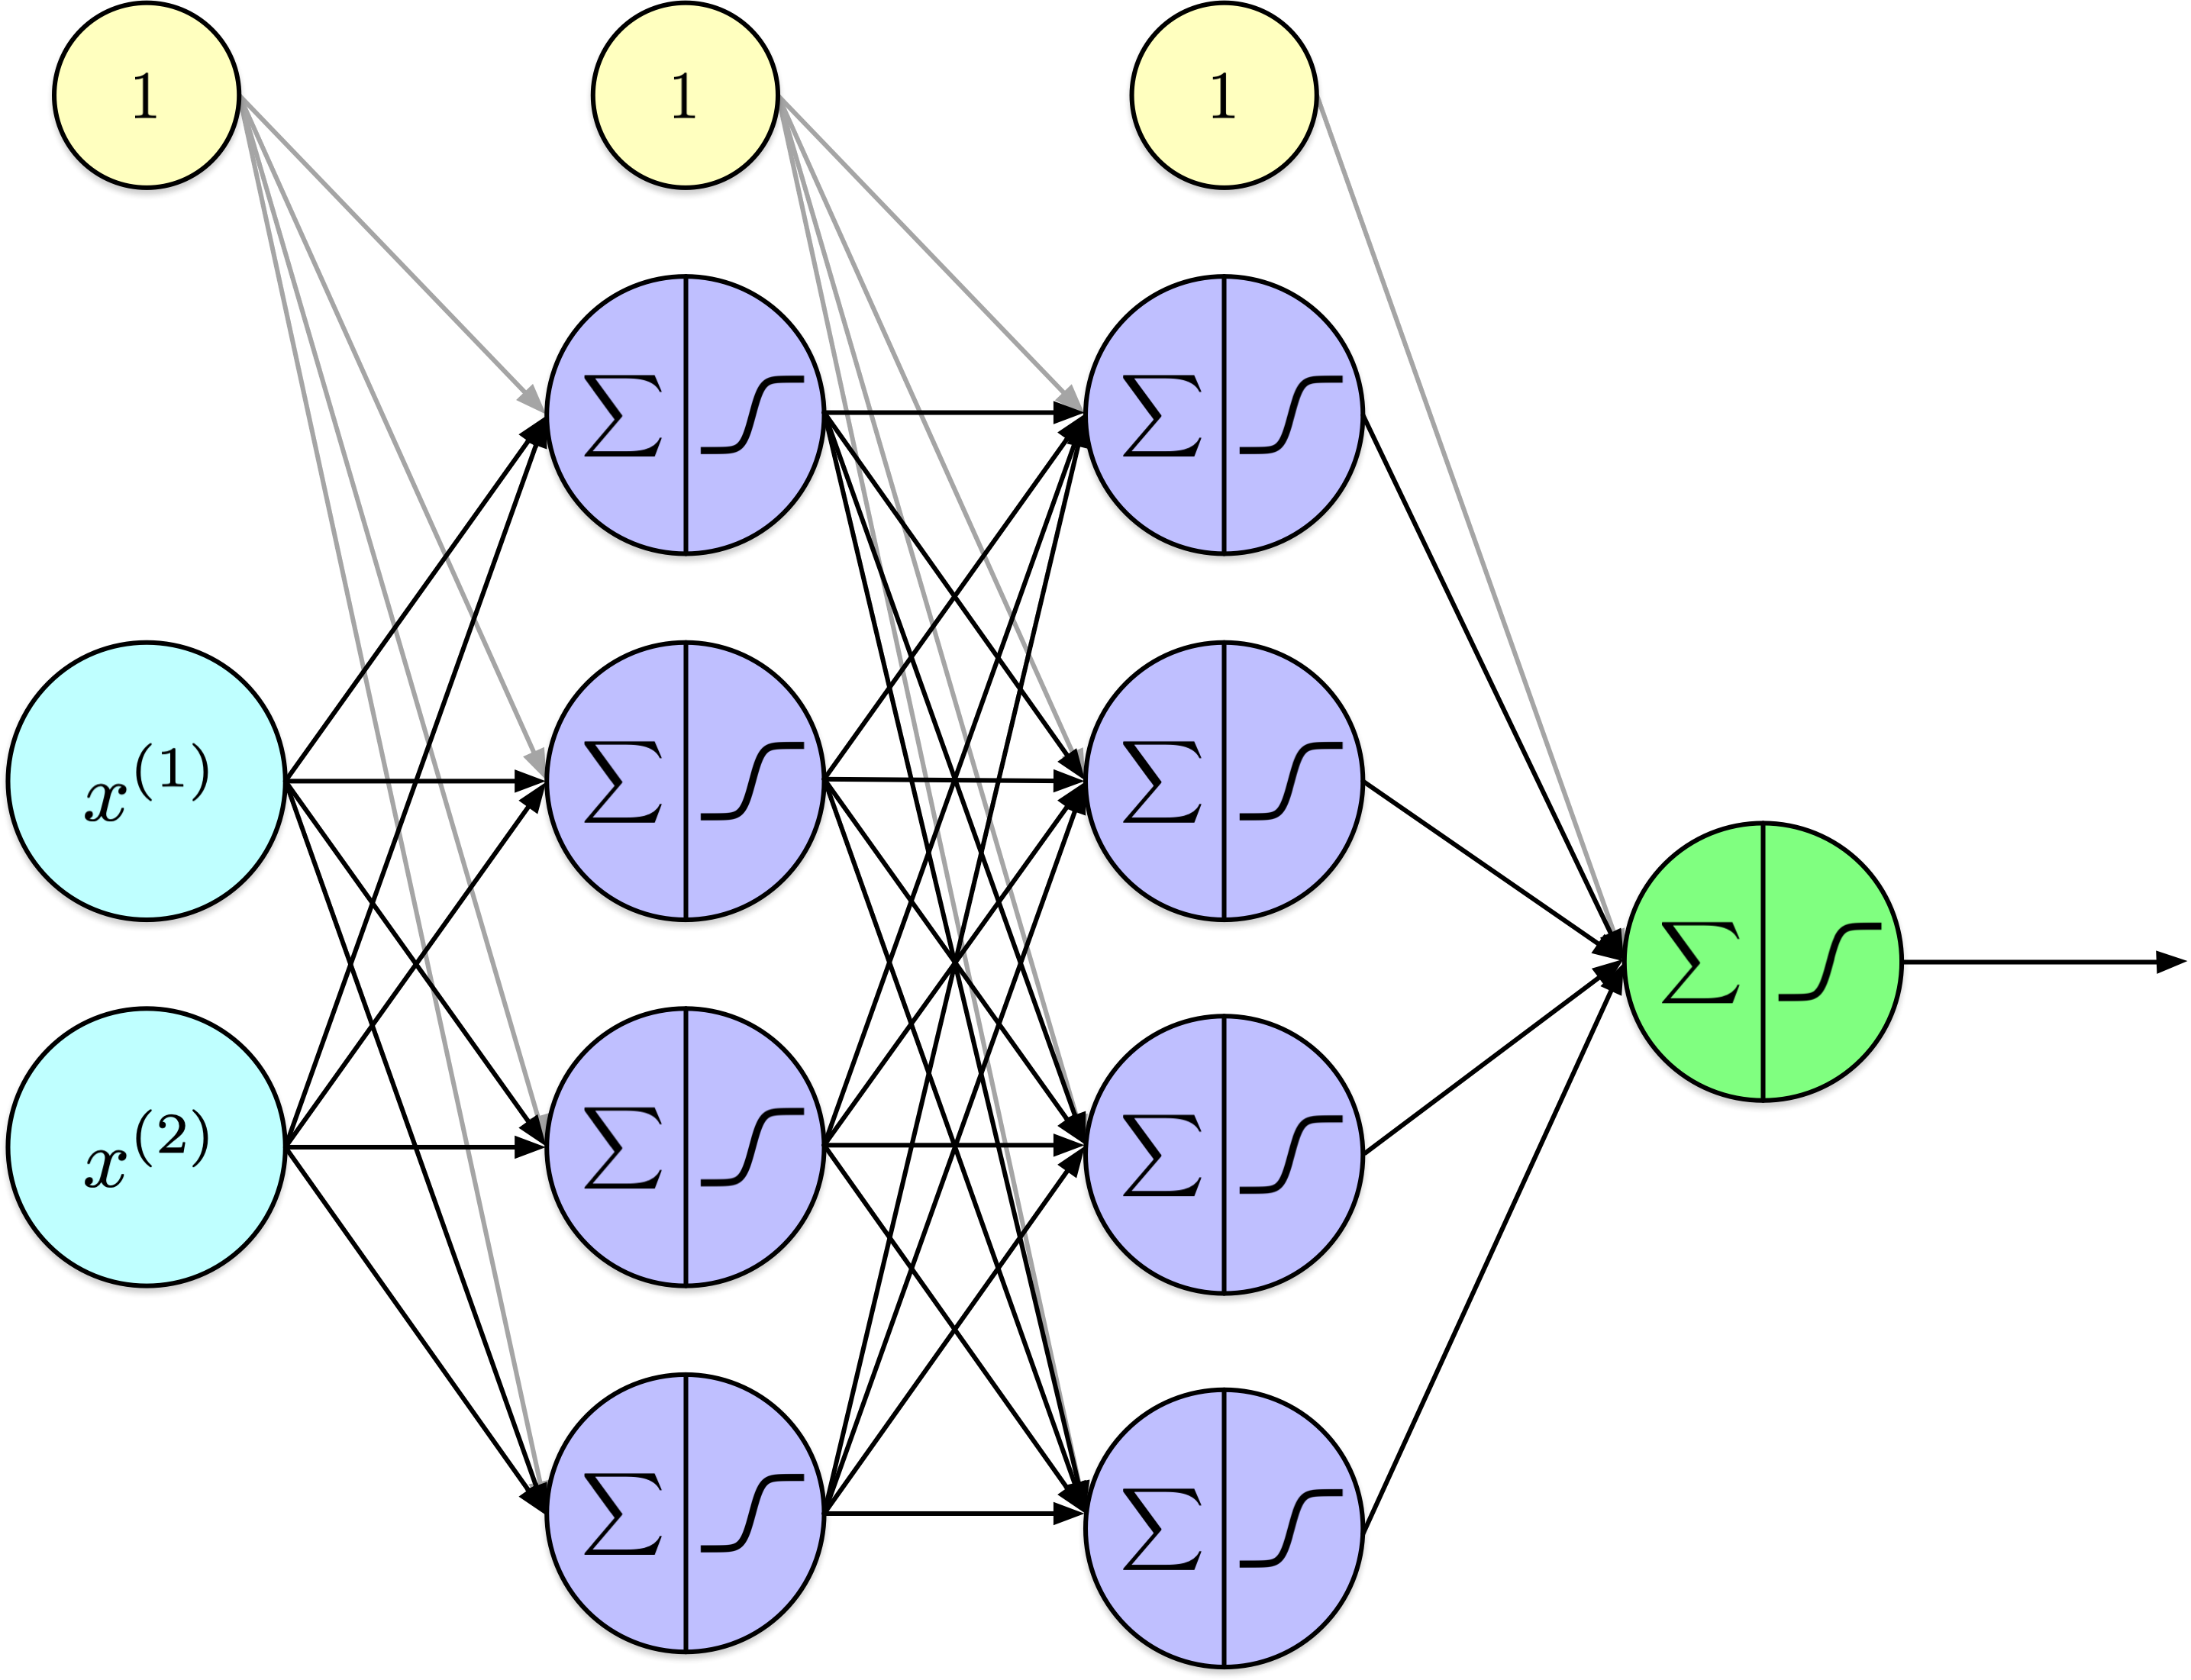

Matrix multiplication requires the number of columns in the incoming
activations to match the number of rows in the weight matrix. The number
of columns in the result is the number of units in the current layer.
Applying the sigmoid elementwise preserves that shape.

Broadcasting does not create a separate trainable bias for each example.
Every example uses the same four biases in a four-unit hidden layer, or
the same single bias in the output layer. This network therefore has 28
weights and 9 biases, for a total of 37 trainable parameters.

## Making predictions

``` python
    def predict(self, X, threshold=0.5):

        return (self.forward(X) >= threshold).astype(int)
```

Indeed, predictions, plural.

The `forward` method produces an array of probabilities, each ranging
from 0 to 1, indicating the likelihood that a particular example, $x_i$,
belongs to class 1. By evaluating the expression
`self.forward(X) >= threshold`, we obtain an array of boolean values:
`True` if the probability is at least the specified `threshold`, and
`False` otherwise. These boolean values are subsequently converted into
binary values of zeros and ones.

It is important to note that adjusting the decision threshold,
`threshold`, allows for the manipulation of the precision-recall
trade-off, providing flexibility in model performance.

## Probabilities, labels, and loss

For an example whose true label is **1**:

| Predicted probability | Class at threshold 0.5 | Binary cross-entropy       |
|:-----------------------|:-----------------------|:-----------------------|
| 0.51                  | 1                      | $-\log(0.51)\approx 0.673$ |
| 0.99                  | 1                      | $-\log(0.99)\approx 0.010$ |

Both predictions are **correct**, but their losses differ.

- `forward(X)` returns **probabilities**.
- `predict(X)` returns **class labels**.
- `loss(X, y)` evaluates the **probabilities** against the targets.

The loss can improve while accuracy stays unchanged. For a positive
example, increasing the predicted probability from 0.51 to 0.99 lowers
binary cross-entropy even though both values produce class 1.
Conversely, a confidently incorrect prediction receives a larger loss.

This is the same binary cross-entropy, or mean negative log-likelihood,
used for logistic regression in Lecture 6. The output of the neural
network replaces the probability computed by the logistic regression
model; the definition of the loss is unchanged.

## Computing the loss

``` python
    def loss(self, X, y):

        return bce_loss(y, self.forward(X))
```

**Quiz:** Why do we use `bce_loss(y, self.forward(X))` rather than
`bce_loss(y, self.predict(X))`?

The method averages binary cross-entropy over the dataset.

**Answer:** `forward(X)` returns probabilities, while `predict(X)`
converts them into class labels. Using probabilities lets the loss
recognize changes in confidence even when the predicted class stays the
same. For example, for a positive example, 0.51 and 0.99 both predict
class 1, but 0.99 has a lower loss. Clipping prevents `log(0)`; it
cannot recover the confidence information discarded by thresholding.

## Discussion

With the exception of the training algorithm, our neural network
implementation is now complete.

For those who are not familiar with the back-propagation algorithm, how
do you propose to learn the parameters of the model?

. . .

Probe parameter changes → record the best individual changes → apply
them together → repeat.

## Pseudocode

``` pseudocode
for each iteration:
    current_loss = compute_loss(network, training_data)
    deltas = {}
    for each parameter p in network:  # weights AND biases
        original_value = value(p)
        best_delta = 0
        best_loss = current_loss
        for delta in [-step, 0, +step]:
            loss_temp = compute_loss_with_replacement(
                p, original_value + delta, training_data)
            if loss_temp < best_loss:
                best_loss = loss_temp
                best_delta = delta
        deltas[p] = best_delta

    # Apply all recorded changes simultaneously
    for each parameter p in network:
        value(p) += deltas[p]
```

This algorithm chooses updates by **trying parameter changes**.
Backpropagation will compute **gradients**, which an optimizer uses to
choose updates. Both fit into a training loop that evaluates the network
and updates its parameters.

Each candidate change is evaluated with every other parameter fixed at
its value at the start of the iteration. The temporary replacement is
undone after the probe. Only after all parameters have been examined are
the recorded changes applied together. In the code, `epochs` counts
these complete parameter sweeps; each sweep evaluates the training set
many times.

A change that lowers loss on its own may interact badly with changes to
other parameters. Applying all selected changes together can therefore
undo good individual choices and increase the total loss. Neither
decreasing loss nor increasing accuracy is guaranteed at every
iteration.

The simultaneous structure connects this example to gradient-based
training: information for all updates is collected using the current
parameters, then the updates are applied. The next lecture replaces the
individual probes with gradients computed by backpropagation.

## Python detour: enumerating parameters

A short Python detour: **generators**, parameter **tags**, and reading
or changing array entries.

``` python
    def _all_param_tags(self):

        """
        Yields tags referencing every scalar parameter:
        ('W', layer_idx, i, j) or ('b', layer_idx, j)
        """

        for l, W in enumerate(self.W):
            for i in range(W.shape[0]):
                for j in range(W.shape[1]):
                    yield ('W', l, i, j)
            for j in range(self.b[l].shape[0]):
                yield ('b', l, j)
```

`_all_param_tags` is a generator: it provides the location of each
scalar weight and bias without building a separate list first. The
following examples explain the Python mechanism used by the training
loop.

## Python detour: generators

A **generator** produces values one at a time, pausing at `yield` and
resuming when the next value is requested.

In [9]:
def countdown(n):
    while n > 0:
        yield n
        n -= 1

In [10]:
c = countdown(3)
print(next(c))  # 3
print(next(c))  # 2
print(next(c))  # 1

3
2
1

Calling `countdown(3)` creates a generator; it does not immediately run
the function body. Each call to `next(c)` resumes the body until the
next `yield`. The local state, including `n`, is retained between calls.

## Python detour: consuming an iterator

After its final value, the generator raises `StopIteration`:

In [11]:
try:
    print(next(c))
except StopIteration:
    print("Caught StopIteration.")

Caught StopIteration.

A `for` loop handles this termination automatically:

In [12]:
for value in countdown(3):
    print(value)

3
2
1

The `for` loop requests successive values until the iterator is
exhausted. There is no need to catch `StopIteration` explicitly in that
form.

The built-ins `enumerate` and `zip` also return iterators.
`enumerate(self.W)` supplies a layer index and its weight matrix, while
`zip(self.W, self.b)` pairs each matrix with its bias vector. The
parameter generator uses nested loops to yield a tag for every
individual weight and bias.

## Python detour: parameter tags

In [13]:
class Demo:

    def __init__(self, layer_sizes):
        self.sizes = list(layer_sizes)
        rng = np.random.default_rng(0)
        self.W = [rng.standard_normal(size=(in_d, out_d)) * 0.5
                  for in_d, out_d in zip(layer_sizes[:-1], layer_sizes[1:])]
        self.b = [np.zeros(out_d) for out_d in layer_sizes[1:]]

    def _all_param_tags(self):

        """
        Yields tags referencing every scalar parameter:
        ('W', layer_idx, i, j) or ('b', layer_idx, j)
        """

        for l, W in enumerate(self.W):
            for i in range(W.shape[0]):
                for j in range(W.shape[1]):
                    yield ('W', l, i, j)
            for j in range(self.b[l].shape[0]):
                yield ('b', l, j)

    def show(self):

      for tag in self._all_param_tags():
        print(tag)

In [14]:
d = Demo([2,4,4,1])
d.show()

('W', 0, 0, 0)
('W', 0, 0, 1)
('W', 0, 0, 2)
('W', 0, 0, 3)
('W', 0, 1, 0)
('W', 0, 1, 1)
('W', 0, 1, 2)
('W', 0, 1, 3)
('b', 0, 0)
('b', 0, 1)
('b', 0, 2)
('b', 0, 3)
('W', 1, 0, 0)
('W', 1, 0, 1)
('W', 1, 0, 2)
('W', 1, 0, 3)
('W', 1, 1, 0)
('W', 1, 1, 1)
('W', 1, 1, 2)
('W', 1, 1, 3)
('W', 1, 2, 0)
('W', 1, 2, 1)
('W', 1, 2, 2)
('W', 1, 2, 3)
('W', 1, 3, 0)
('W', 1, 3, 1)
('W', 1, 3, 2)
('W', 1, 3, 3)
('b', 1, 0)
('b', 1, 1)
('b', 1, 2)
('b', 1, 3)
('W', 2, 0, 0)
('W', 2, 1, 0)
('W', 2, 2, 0)
('W', 2, 3, 0)
('b', 2, 0)

## Python detour: reading a parameter

``` python
    def _get_param(self, tag):
        kind = tag[0]
        if kind == 'W':
            _, l, i, j = tag
            return self.W[l][i, j]
        else:
            _, l, j = tag
            return self.b[l][j]
```

Given a `tag`, either `('W', l, i, j)` or `('b', l, j)`, the method
retrieves the weight or the bias term corresponding to the provided
indices. `l` designates the **layer**; `i` and `j` are row and column
indices of `W[l]`, or `j` is an index in `b[l]`.

## Python detour: changing a parameter

``` python
    def _set_param(self, tag, val):
        kind = tag[0]
        if kind == 'W':
            _, l, i, j = tag
            self.W[l][i, j] = val
        else:
            _, l, j = tag
            self.b[l][j] = val
```

Similar logic, but the method updates `self.W[l][i, j]` or
`self.b[l][j] = val`, depending on the type of tag.

## Training (learning)

The Python detour is complete. These helpers let the training loop probe
and update **every weight and bias**.

``` python
    def train(self, X, y, epochs=10, verbose=True):

        for ep in range(1, epochs + 1):

            base_loss = self.loss(X, y)
            updates = {}

            # Probe all parameters
            for tag in self._all_param_tags():

                theta = self._get_param(tag)
                best_delta = 0.0
                best_loss = base_loss

                for delta in (-self.step, 0.0, +self.step):
                    self._set_param(tag, theta + delta)
                    trial_loss = self.loss(X, y)
                    if trial_loss < best_loss:
                        best_loss = trial_loss
                        best_delta = delta

                # restore original
                self._set_param(tag, theta)
                updates[tag] = best_delta

            # Apply all deltas together
            for tag, d in updates.items():
                if d != 0.0:
                    self._set_param(tag, self._get_param(tag) + d)

            new_loss = self.loss(X, y)

            if verbose:
                print(f"Epoch {ep:3d}: loss {base_loss:.5f} → {new_loss:.5f}")

            # optional early stop
            if abs(new_loss - base_loss) < 1e-12:
                break
```

The probes use the same baseline parameters, and each parameter is
restored before the next one is examined. The dictionary stores the
selected changes; the second loop applies them simultaneously. Because
interactions are ignored during selection, the combined update can
increase loss even when every nonzero change helped in isolation.

The stopping condition checks whether the change in training loss is
very small. This is a simple stopping rule for the demonstration, not a
guarantee of an optimal solution or successful generalization.

## Training on circles

Does it work?

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = NaiveMLP([2, 4, 4, 1], step=0.06, seed=0)

print("Initial loss:", model.loss(X_train, y_train))

model.train(X_train, y_train, epochs=100)

print("Train acc:", accuracy_score(y_train, model.predict(X_train)))
print("Test acc: ", accuracy_score(y_test, model.predict(X_test)))

Initial loss: 0.7001969055705487
Epoch   1: loss 0.70020 → 0.69315
Epoch   2: loss 0.69315 → 0.69547
Epoch   3: loss 0.69547 → 0.69387
Epoch   4: loss 0.69387 → 0.69542
Epoch   5: loss 0.69542 → 0.69384
Epoch   6: loss 0.69384 → 0.69537
Epoch   7: loss 0.69537 → 0.69382
Epoch   8: loss 0.69382 → 0.69531
Epoch   9: loss 0.69531 → 0.69379
Epoch  10: loss 0.69379 → 0.69525
Epoch  11: loss 0.69525 → 0.69361
Epoch  12: loss 0.69361 → 0.69517
Epoch  13: loss 0.69517 → 0.69331
Epoch  14: loss 0.69331 → 0.69503
Epoch  15: loss 0.69503 → 0.69298
Epoch  16: loss 0.69298 → 0.69468
Epoch  17: loss 0.69468 → 0.69257
Epoch  18: loss 0.69257 → 0.69364
Epoch  19: loss 0.69364 → 0.69200
Epoch  20: loss 0.69200 → 0.69173
Epoch  21: loss 0.69173 → 0.69118
Epoch  22: loss 0.69118 → 0.68965
Epoch  23: loss 0.68965 → 0.68970
Epoch  24: loss 0.68970 → 0.68716
Epoch  25: loss 0.68716 → 0.68672
Epoch  26: loss 0.68672 → 0.68417
Epoch  27: loss 0.68417 → 0.68170
Epoch  28: loss 0.68170 → 0.67855
Epoch  29: loss

These results illustrate that the naïve algorithm can learn a useful
decision boundary. They do not guarantee success for other
initializations, step sizes, or datasets. Keep the test set separate
from training and parameter-setting choices; validation data are
appropriate for selecting such settings. The fixed `step` and `seed`
make this demonstration reproducible.

## Visualization

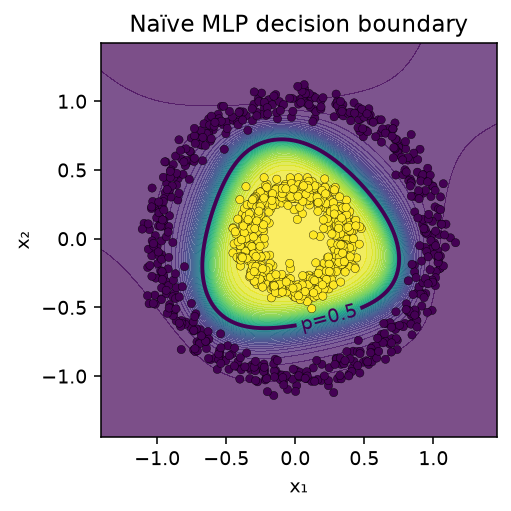

In [16]:
# Plot helper: decision boundary in the original (x1, x2) plane

def plot_decision_boundary(model, X, y, title="Naïve MLP decision boundary"):

    # grid over the input plane
    pad = 0.3
    x1_min, x1_max = X[:,0].min()-pad, X[:,0].max()+pad
    x2_min, x2_max = X[:,1].min()-pad, X[:,1].max()+pad

    xx, yy = np.meshgrid(
        np.linspace(x1_min, x1_max, 400),
        np.linspace(x2_min, x2_max, 400)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]

    # predict probabilities on the grid
    p = model.forward(grid).reshape(xx.shape)

    # filled probabilities + p=0.5 contour + data points
    plt.figure(figsize=(3.75, 3.75), dpi=140)
    plt.contourf(xx, yy, p, levels=50, alpha=0.7)
    cs = plt.contour(xx, yy, p, levels=[0.5], linewidths=2)
    plt.scatter(X[:,0], X[:,1], c=y, s=18, edgecolor="k", linewidth=0.2)
    plt.clabel(cs, fmt={0.5: "p=0.5"})
    plt.title(title)
    plt.xlabel("x₁")
    plt.ylabel("x₂")
    plt.tight_layout()
    plt.show()

plot_decision_boundary(model, X, y)

## XNOR-like data

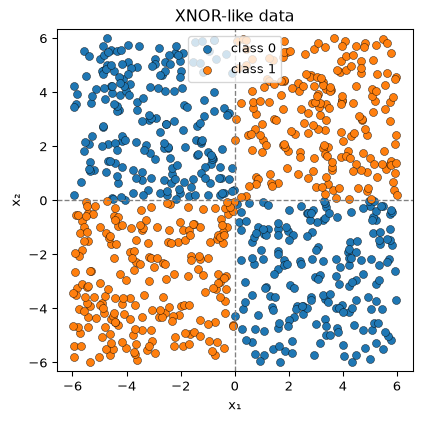

In [17]:
n_samples = 800
rng = np.random.default_rng(42)

X = rng.uniform(-6, 6, size=(n_samples, 2))
x1, x2 = X[:, 0], X[:, 1]

y = ((x1 * x2) > 0).astype(int)

plt.figure(figsize=(4.5, 4.5))
plt.scatter(X[y == 0, 0], X[y == 0, 1],
            color="C0", label="class 0", edgecolor="k", linewidth=0.3)
plt.scatter(X[y == 1, 0], X[y == 1, 1],
            color="C1", label="class 1", edgecolor="k", linewidth=0.3)

plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.axvline(0, color="gray", linestyle="--", linewidth=1)

plt.xlabel("x₁")
plt.ylabel("x₂")
plt.title("XNOR-like data")
plt.xlim(-6, 6)
plt.ylim(-6, 6)
plt.axis("equal")
plt.legend()
plt.tight_layout()
plt.show()

XNOR is the complement of XOR: class 1 corresponds to sampled inputs
with matching signs. Both problems require a nonlinear decision
boundary. The seed and step size were chosen to provide a clear,
reproducible demonstration; the naïve algorithm remains sensitive to
these choices.

The architecture remains `[2, 4, 4, 1]`. Training determines different
parameter values for this new dataset.

## XNOR-like data (continued)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = NaiveMLP([2, 4, 4, 1], step=0.06, seed=0)

print("Initial loss:", model.loss(X_train, y_train))

model.train(X_train, y_train, epochs=100, verbose=False)

print("Final loss:", model.loss(X_train, y_train))

print("Train acc:", accuracy_score(y_train, model.predict(X_train)))
print("Test acc: ", accuracy_score(y_test, model.predict(X_test)))

Initial loss: 0.7029764953722529
Final loss: 0.09228049882862682
Train acc: 0.9866666666666667
Test acc:  0.98

## XNOR-like data (continued)

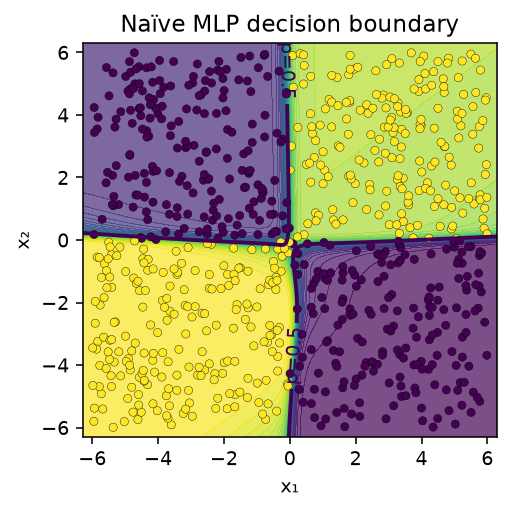

In [19]:
plot_decision_boundary(model, X, y)

Our simple neural network, along with its naïve training algorithm, was
evaluated on two distinct tests. Despite the simplicity of the model, it
successfully learned significantly different decision boundaries without
necessitating the engineering of additional features.

For the sake of simplicity and clarity in this example, we utilized the
raw data without applying any scaling. However, in practical scenarios,
it is customary to scale or normalize features prior to training neural
networks or any models that rely on gradient-based optimization. Scaling
facilitates faster and more stable convergence of training algorithms,
although it introduces additional preprocessing and postprocessing
steps. Since the primary objective here is to comprehend the training
mechanism rather than optimize for efficiency, we have deliberately
chosen to omit scaling in this instance.

Before training,

``` python
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)
```

When plotting in the original feature space, construct the grid in the
original coordinates and pass `scaler.transform(grid)` to
`model.forward`. The predictions can then be plotted against the
unchanged original grid. The model must receive inputs transformed in
the same way as its training data.

## Drawbacks

- **Repeated evaluations:** each parameter probe recomputes predictions
  and loss on the training set.
- **Fixed step size:** the available changes are only `-step`, `0`, and
  `+step`.
- **Parameter interactions:** individually helpful changes can conflict
  when applied together.
- **Sensitivity:** results depend on initialization, step size, and the
  dataset.

The method learns from comparisons of losses. These comparisons provide
some directional information about the tested changes, but they do not
compute a gradient or use its magnitude to select an update.

A small fixed step may make progress slow, while a large step may skip
useful parameter values or cause oscillations. Since all recorded
changes are applied together, loss can rise even when individual probes
suggested improvements.

Generalization still requires a separate evaluation, as it does for
gradient-based training. Overfitting and the need for regularization are
not distinctive limitations of this naïve method.

## Why a faster method is needed

Our small network has **37 parameters**.

- Three probes per parameter: $3\times 37=111$ loss evaluations.
- One baseline and one final evaluation: **113 evaluations per sweep**.
- Every evaluation runs the network on the **whole training set**.

Backpropagation computes all parameter gradients using a **forward
pass** and a **backward pass**. An optimizer then updates the parameters
together.

The count describes the implementation shown here, including its
zero-change probes. It exposes the cost of repeatedly running a network
whose computation we already understand. For a network with many
parameters, repeating full evaluations for every parameter becomes
expensive.

Backpropagation reuses intermediate results to compute gradients
efficiently. Its work still grows with network size; it avoids a
separate full-network probe for every scalar parameter. A gradient-based
update also requires an appropriate learning rate and does not guarantee
that every update lowers loss.

# Closing

## Summary

- Implemented a **complete feedforward network** using NumPy arrays.
- Traced the **shapes** of **inputs**, **weights**, **biases**, and
  **layer outputs**.
- Distinguished **predicted probabilities**, **class labels**, and
  **binary cross-entropy**.
- Used a **naïve derivative-free method** to collect parameter changes
  and apply them simultaneously.
- Connected **repeated loss evaluations** and **parameter interactions**
  to the need for an efficient gradient computation.

## Next lecture

- Layer notation, the chain rule, and backpropagation.
- Gradient-based training and the behavior of activation derivatives.

## References

Russell, Stuart, and Peter Norvig. 2020. *Artificial Intelligence: A
Modern Approach*. 4th ed. Pearson. <http://aima.cs.berkeley.edu/>.

------------------------------------------------------------------------

Marcel **Turcotte**

<Marcel.Turcotte@uOttawa.ca>

School of Electrical Engineering and **Computer Science** (EE**CS**)

University of Ottawa